In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("../data/spacex_cleaned.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())

# Check data types
df.info()

Dataset loaded successfully!
Dataset Shape: (90, 19)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class,Year
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0,2010
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0,2012
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0,2013
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0,2013
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0,2013


<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     str    
 2   BoosterVersion  90 non-null     str    
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     str    
 5   LaunchSite      90 non-null     str    
 6   Outcome         90 non-null     str    
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     str    
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     str    
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
 17  Class           90 non-null     int64  
 18  Yea

In [2]:
# Check target variable distribution
print("Landing Class Distribution:")
print(df["Class"].value_counts())

# Check percentage distribution
print("\nLanding Class Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Landing Class Distribution:
Class
1    60
0    30
Name: count, dtype: int64

Landing Class Percentage:
Class
1    66.666667
0    33.333333
Name: proportion, dtype: float64

Missing Values:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
Class              0
Year               0
dtype: int64


In [3]:
# Create a copy of the dataset
data = df.copy()

# Drop unnecessary columns
data = data.drop(columns=[
    "Date",
    "BoosterVersion",
    "Outcome",
    "LandingPad",
    "Serial",
    "Longitude",
    "Latitude"
])

# Check remaining columns
print("Remaining Columns:")
print(data.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Display dataset shape
print("\nDataset Shape:", data.shape)

Remaining Columns:
['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Class', 'Year']

Missing Values:
FlightNumber    0
PayloadMass     0
Orbit           0
LaunchSite      0
Flights         0
GridFins        0
Reused          0
Legs            0
Block           0
ReusedCount     0
Class           0
Year            0
dtype: int64

Dataset Shape: (90, 12)


In [4]:
# Convert categorical columns into numerical columns
data = pd.get_dummies(
    data,
    columns=["Orbit", "LaunchSite"],
    dtype=int
)

# Display updated columns
print("Updated Columns:")
print(data.columns.tolist())

# Display first 5 rows
display(data.head())

# Check dataset shape
print("\nUpdated Dataset Shape:", data.shape)

Updated Columns:
['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Class', 'Year', 'Orbit_ES-L1', 'Orbit_GEO', 'Orbit_GTO', 'Orbit_HEO', 'Orbit_ISS', 'Orbit_LEO', 'Orbit_MEO', 'Orbit_PO', 'Orbit_SO', 'Orbit_SSO', 'Orbit_VLEO', 'LaunchSite_CCAFS SLC 40', 'LaunchSite_KSC LC 39A', 'LaunchSite_VAFB SLC 4E']


,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Class,Year,...,Orbit_ISS,Orbit_LEO,Orbit_MEO,Orbit_PO,Orbit_SO,Orbit_SSO,Orbit_VLEO,LaunchSite_CCAFS SLC 40,LaunchSite_KSC LC 39A,LaunchSite_VAFB SLC 4E
0,1,6104.959412,1,False,False,False,1.0,0,0,2010,...,0,1,0,0,0,0,0,1,0,0
1,2,525.000000,1,False,False,False,1.0,0,0,2012,...,0,1,0,0,0,0,0,1,0,0
2,3,677.000000,1,False,False,False,1.0,0,0,2013,...,1,0,0,0,0,0,0,1,0,0
3,4,500.000000,1,False,False,False,1.0,0,0,2013,...,0,0,0,1,0,0,0,0,0,1
4,5,3170.000000,1,False,False,False,1.0,0,0,2013,...,0,0,0,0,0,0,0,1,0,0



Updated Dataset Shape: (90, 24)


In [5]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target variable (y)
X = data.drop("Class", axis=1)
y = data["Class"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (72, 23)
Testing Data Shape: (18, 23)

Training Target Distribution:
Class
1    48
0    24
Name: count, dtype: int64

Testing Target Distribution:
Class
1    12
0     6
Name: count, dtype: int64


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("---------------------------")
print("Model Accuracy:", round(lr_accuracy * 100, 2), "%")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results
---------------------------
Model Accuracy: 77.78 %

Confusion Matrix:
[[ 2  4]
 [ 0 12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         6
           1       0.75      1.00      0.86        12

    accuracy                           0.78        18
   macro avg       0.88      0.67      0.68        18
weighted avg       0.83      0.78      0.74        18



c:\Users\nikhi\OneDrive\Desktop\SPACE_X_CAPSTONE\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create a pipeline with feature scaling
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=3000))
])

# Train model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Improved Logistic Regression Results")
print("-----------------------------------")
print("Model Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Improved Logistic Regression Results
-----------------------------------
Model Accuracy: 77.78 %

Confusion Matrix:
[[ 2  4]
 [ 0 12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         6
           1       0.75      1.00      0.86        12

    accuracy                           0.78        18
   macro avg       0.88      0.67      0.68        18
weighted avg       0.83      0.78      0.74        18



In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("---------------------")
print("Model Accuracy:", round(dt_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Results
---------------------
Model Accuracy: 94.44 %

Confusion Matrix:
[[ 5  1]
 [ 0 12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91         6
           1       0.92      1.00      0.96        12

    accuracy                           0.94        18
   macro avg       0.96      0.92      0.93        18
weighted avg       0.95      0.94      0.94        18



In [9]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create SVM model with feature scaling
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", random_state=42))
])

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Results")
print("-----------")
print("Model Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Results
-----------
Model Accuracy: 77.78 %

Confusion Matrix:
[[ 2  4]
 [ 0 12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         6
           1       0.75      1.00      0.86        12

    accuracy                           0.78        18
   macro avg       0.88      0.67      0.68        18
weighted avg       0.83      0.78      0.74        18



Machine Learning Model Comparison


,Model,Accuracy
0,Logistic Regression,77.777778
1,Decision Tree,94.444444
2,SVM,77.777778



Best Performing Model: Decision Tree
Best Accuracy: 94.44 %


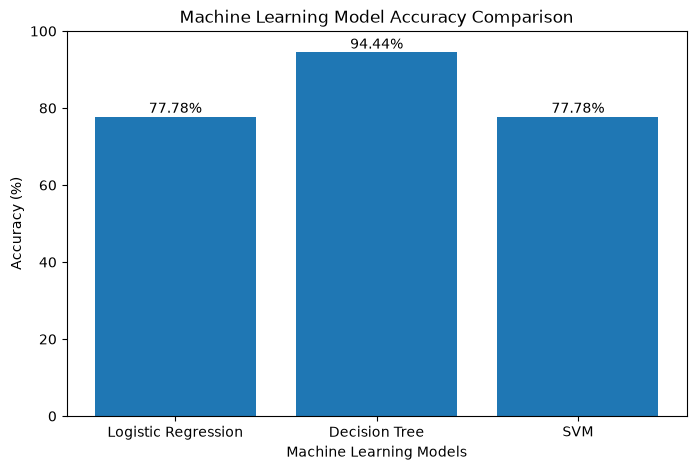

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Compare model accuracies
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "SVM"
    ],
    "Accuracy": [
        lr_accuracy * 100,
        dt_accuracy * 100,
        svm_accuracy * 100
    ]
})

# Display comparison table
print("Machine Learning Model Comparison")
display(model_comparison)

# Find best model
best_model = model_comparison.loc[
    model_comparison["Accuracy"].idxmax()
]

print("\nBest Performing Model:", best_model["Model"])
print("Best Accuracy:", round(best_model["Accuracy"], 2), "%")

# Plot comparison
plt.figure(figsize=(8, 5))
plt.bar(model_comparison["Model"], model_comparison["Accuracy"])
plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(model_comparison["Accuracy"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Define 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf"))
    ])
}

# Evaluate models
results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Average Accuracy": scores.mean() * 100,
        "Standard Deviation": scores.std() * 100
    })

# Display results
cv_results = pd.DataFrame(results)

print("5-Fold Cross-Validation Results:")
display(cv_results.round(2))

5-Fold Cross-Validation Results:


,Model,Average Accuracy,Standard Deviation
0,Logistic Regression,82.22,6.48
1,Decision Tree,84.44,6.48
2,SVM,81.11,6.67


In [13]:
import joblib

# Create and train the final Decision Tree model
final_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

final_model.fit(X, y)

# Save model and feature names
model_data = {
    "model": final_model,
    "features": X.columns.tolist()
}

joblib.dump(
    model_data,
    "../models/spacex_landing_model.pkl"
)

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


## Conclusion

The SpaceX Falcon 9 First Stage Landing Prediction project aimed to analyze historical launch data and predict whether the first-stage booster would land successfully.

The project involved data collection, data cleaning, exploratory data analysis, SQL queries, data visualization, interactive mapping, dashboard development, and machine learning.

Three machine learning algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. Support Vector Machine (SVM)

The Decision Tree model achieved the highest test accuracy of 94.44%, while its average 5-fold cross-validation accuracy was 84.44%.

The analysis also showed that landing success varied across launch sites, orbit types, payload masses, and other launch characteristics.

This project demonstrates how data science and machine learning can be used to analyze historical spaceflight data and support predictions about rocket booster landing outcomes.

The results are promising, although further testing with a larger and more diverse dataset would be necessary before using the model for real-world launch decisions.
